# Organ Transplant Waitlist Outcome Prediction
## Random Forest Model Evaluation, Confusion Matrix Analysis & Official Benchmarking

**Organization:** Break Through Tech AI Studio / MediMate Foundation  
**Milestone:** November Model Development & Evaluation (Task #3 Deliverable)  
**Authors / Contributors:** Healthcare 1C Team  

---

### Notebook Overview & Objectives:
Following our baseline logistic regression evaluation, this notebook evaluates the newly developed **Random Forest Classifiers** (Baseline A and Baseline B) for predicting 1-year adverse waitlist outcomes (`adverse_365`):
1. **Reusable Evaluation Function (Coding Task 1):** An automated, flexible evaluation function calculating primary clinical ranking and probabilistic calibration metrics: **ROC-AUC**, **PR-AUC (Average Precision)**, and **Brier Score**, alongside diagnostic metrics (Balanced Accuracy, Log Loss, Sensitivity/Recall, Specificity, Precision, and F1).
2. **Confusion Matrix Generation & Visualization (Coding Task 2):** A reusable plotting function displaying raw patient counts, total percentages, and quadrant annotations (True Negatives, False Positives, False Negatives, True Positives) to analyze the model's performance at default ($0.50$) vs. calibrated clinical thresholds.
3. **Official Benchmark Comparison Table (Deliverable):** A comprehensive grading comparison evaluating **Random Forest Baselines A & B** against **Logistic Regression Baselines A & B** and official MediMate / Break Through Tech project targets.
4. **Comparative ROC & Precision-Recall Curves:** Side-by-side performance curves demonstrating the non-linear improvements of Random Forest over linear logistic regression baselines.
5. **Clinical Threshold Calibration & Sensitivity Trade-offs:** Optimizing the probability cutoff to transition the Random Forest from 0% recall to actionable clinical detection.

In [10]:
# 1. Imports and environment setup
from pathlib import Path
import json
import pickle
import warnings
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Silence cross-version pickle warnings and matplotlib font warnings
warnings.filterwarnings('ignore')

# Set aesthetic visualization style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("All dependencies successfully imported.")

All dependencies successfully imported.


---
## 2. Load Processed Dataset & Reproduce the Held-Out Test Split

We load the standardized processed dataset (`X_processed.csv` and `y_processed.csv`) and recreate the exact stratified 80/20 train/test split with `random_state=42`. This ensures an apples-to-apples evaluation across all models and notebooks.

In [11]:
# Detect project root directory (works whether notebook is run from root or notebooks/)
ROOT_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents] 
                 if (p / 'processed_output' / 'X_processed.csv').exists() or 
                    (p / 'processed datasets' / 'X_processed.csv').exists()), None)
if ROOT_DIR is None:
    raise FileNotFoundError("Could not locate 'processed_output/X_processed.csv'. Check working directory.")

DATA_DIR = ROOT_DIR / 'processed_output' if (ROOT_DIR / 'processed_output').exists() else ROOT_DIR / 'processed datasets'
MODEL_DIR = ROOT_DIR / 'models'

print(f"Project Root Directory: {ROOT_DIR}")
print(f"Data Directory: {DATA_DIR}")
print(f"Model Directory: {MODEL_DIR}")

# Load processed feature matrix and outcome target
X_processed = pd.read_csv(DATA_DIR / 'X_processed.csv', index_col=0)
y_processed = pd.read_csv(DATA_DIR / 'y_processed.csv', index_col=0).iloc[:, 0]

print(f"Full Dataset: {X_processed.shape[0]:,} rows, {X_processed.shape[1]} features")
print(f"Adverse Event Prevalence: {y_processed.mean():.4%} ({y_processed.sum():,} positive cases)")

# Recreate the exact stratified 80/20 train/test split (seed 42)
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y_processed,
    test_size=0.2,
    random_state=42,
    stratify=y_processed
)

print(f"Test Set Size: {X_test.shape[0]:,} patients ({y_test.sum():,} adverse events, {(1 - y_test.mean()):.2%} non-adverse)")

Project Root Directory: /Users/mosopefoluwajohn/Desktop/Fall AI Studio - Healthcare 1C/Healthcare-1C-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation
Data Directory: /Users/mosopefoluwajohn/Desktop/Fall AI Studio - Healthcare 1C/Healthcare-1C-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/processed_output
Model Directory: /Users/mosopefoluwajohn/Desktop/Fall AI Studio - Healthcare 1C/Healthcare-1C-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/models
Full Dataset: 439,887 rows, 51 features
Adverse Event Prevalence: 3.9981% (17,587 positive cases)
Test Set Size: 87,978 patients (3,517 adverse events, 96.00% non-adverse)


---
## 3. Load or Train Optimized Random Forest Models

We load the hyperparameter tuning metadata for:
* **Random Forest Baseline A (`models/random_forest_baseline_a_metadata.json`):** 30 clinical features (excludes race, gender, and region).
* **Random Forest Baseline B (`models/random_forest_baseline_b_metadata.json`):** 51 clinical, demographic, and geographic features.

If pre-fitted pickle files (`.pkl`) exist in `models/`, we load them directly. Otherwise, the helper function uses the recorded `best_parameters` to fit the classifier on `X_train` with `random_state=42`, automatically saving the model for instant future loading.

In [12]:
# Helper function to load pre-fitted RF model or fit using recorded optimal hyperparameters
def load_or_train_rf_model(baseline_letter: str):
    prefix = f"random_forest_baseline_{baseline_letter.lower()}"
    meta_path = MODEL_DIR / f"{prefix}_metadata.json"
    model_path = MODEL_DIR / f"{prefix}_best.pkl"
    
    if not meta_path.exists():
        raise FileNotFoundError(f"Metadata file not found: {meta_path}")
        
    with open(meta_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)
        
    feature_cols = metadata["feature_columns"]
    best_params = metadata["best_parameters"]
    
    # If pickled model exists, load it
    if model_path.exists():
        print(f"Loading pre-fitted {prefix} from pickle...")
        with open(model_path, "rb") as f:
            model = pickle.load(f)
    else:
        print(f"Pickle not found for {prefix}. Training model with optimal tuned parameters...")
        print(f"  Hyperparameters: {best_params}")
        model = RandomForestClassifier(
            **best_params,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )
        model.fit(X_train[feature_cols], y_train)
        
        # Save fitted model for future runs
        try:
            with open(model_path, "wb") as f:
                pickle.dump(model, f, protocol=pickle.HIGHEST_PROTOCOL)
            print(f"  Fitted model saved to {model_path.name}")
        except Exception as e:
            print(f"  Could not cache pickle locally ({e}); proceeding in memory.")
            
    return model, metadata, feature_cols

# Load/train both Random Forest baselines
rf_model_a, rf_meta_a, rf_features_a = load_or_train_rf_model('a')
rf_model_b, rf_meta_b, rf_features_b = load_or_train_rf_model('b')

# Generate predicted probabilities on the held-out test set
rf_proba_a = rf_model_a.predict_proba(X_test[rf_features_a])[:, 1]
rf_proba_b = rf_model_b.predict_proba(X_test[rf_features_b])[:, 1]

# Default predictions at 0.5 threshold
rf_pred_a_default = (rf_proba_a >= 0.5).astype(int)
rf_pred_b_default = (rf_proba_b >= 0.5).astype(int)

# Load Logistic Regression test probabilities for comparison
def load_logreg_probabilities():
    try:
        with open(MODEL_DIR / "logistic_regression_baseline_a_metadata.json", "r") as f:
            lr_meta_a = json.load(f)
        with open(MODEL_DIR / "logistic_regression_baseline_a_best.pkl", "rb") as f:
            lr_model_a = pickle.load(f)
        with open(MODEL_DIR / "logistic_regression_baseline_b_metadata.json", "r") as f:
            lr_meta_b = json.load(f)
        with open(MODEL_DIR / "logistic_regression_baseline_b_best.pkl", "rb") as f:
            lr_model_b = pickle.load(f)
            
        # Ensure compatibility
        for m in (lr_model_a, lr_model_b):
            step = m.named_steps.get('logistic')
            if step and not hasattr(step, 'multi_class'):
                step.multi_class = 'auto'
                
        lr_proba_a = lr_model_a.predict_proba(X_test[lr_meta_a["feature_columns"]])[:, 1]
        lr_proba_b = lr_model_b.predict_proba(X_test[lr_meta_b["feature_columns"]])[:, 1]
        return lr_proba_a, lr_proba_b
    except Exception as e:
        print(f"Note: Could not load Logistic Regression models for comparison ({e}).")
        return None, None

lr_proba_a, lr_proba_b = load_logreg_probabilities()

print(f"\nRandom Forest Baseline A: Range [{rf_proba_a.min():.4f}, {rf_proba_a.max():.4f}] | Mean = {rf_proba_a.mean():.4f}")
print(f"Random Forest Baseline B: Range [{rf_proba_b.min():.4f}, {rf_proba_b.max():.4f}] | Mean = {rf_proba_b.mean():.4f}")

Loading pre-fitted random_forest_baseline_a from pickle...
Loading pre-fitted random_forest_baseline_b from pickle...

Random Forest Baseline A: Range [0.0032, 0.4858] | Mean = 0.0399
Random Forest Baseline B: Range [0.0001, 0.3024] | Mean = 0.0399


---
## 4. Coding Task 1: Reusable Evaluation Function

The function `evaluate_predictions` calculates:
1. **Primary Ranking & Calibration Metrics:**
   - **ROC-AUC:** Area under the ROC curve (discriminative ability across all thresholds).
   - **PR-AUC (Average Precision):** Area under the Precision-Recall curve (the most critical ranking metric for rare 4.0% events).
   - **Brier Score:** Mean squared difference between predicted probabilities and observed outcomes (measures calibration; target $\le 0.18$).
   - **Log Loss:** Cross-entropy penalization for probabilistic uncertainty.
2. **Threshold-Dependent Diagnostic Metrics:**
   - **Accuracy, Balanced Accuracy, Sensitivity (Recall), Specificity, Precision, and F1 Score.**
   - Full confusion matrix counts: **True Positives (TP), False Positives (FP), True Negatives (TN), False Negatives (FN).**

In [13]:
def evaluate_predictions(
    y_true: pd.Series | np.ndarray,
    y_pred_proba: np.ndarray,
    threshold: float = 0.5,
    model_name: str = "Model"
) -> pd.Series:
    """
    Reusable evaluation function for binary classification models with rare clinical outcomes.
    
    Parameters:
    -----------
    y_true : pd.Series or np.ndarray
        True binary class labels (0 = no adverse event, 1 = adverse event).
    y_pred_proba : np.ndarray
        Predicted probabilities for the positive class (class 1).
    threshold : float, default=0.5
        Decision threshold for converting probabilities into binary class predictions.
    model_name : str, default='Model'
        Label identifier for the model.
        
    Returns:
    --------
    pd.Series
        Structured summary of ranking, calibration, and classification metrics.
    """
    y_true = np.asarray(y_true)
    y_pred = (y_pred_proba >= threshold).astype(int)
    
    # 1. Ranking and Probabilistic Calibration Metrics
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    pr_auc = average_precision_score(y_true, y_pred_proba)
    brier = brier_score_loss(y_true, y_pred_proba)
    logloss = log_loss(y_true, y_pred_proba)
    
    # 2. Threshold-Dependent Binary Classification Metrics
    acc = accuracy_score(y_true, y_pred)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # Confusion matrix components
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    metrics = {
        "Model": model_name,
        "Threshold": threshold,
        "ROC-AUC": roc_auc,
        "PR-AUC (Avg Precision)": pr_auc,
        "Brier Score": brier,
        "Log Loss": logloss,
        "Accuracy": acc,
        "Balanced Accuracy": balanced_acc,
        "Sensitivity (Recall)": recall,
        "Specificity": specificity,
        "Precision": precision,
        "F1 Score": f1,
        "True Positives (TP)": int(tp),
        "False Positives (FP)": int(fp),
        "True Negatives (TN)": int(tn),
        "False Negatives (FN)": int(fn)
    }
    
    return pd.Series(metrics, name=model_name)

# Evaluate Random Forest Baselines at the default 0.5 cutoff
eval_rf_a_default = evaluate_predictions(y_test, rf_proba_a, threshold=0.5, model_name="Random Forest A (Default 0.5)")
eval_rf_b_default = evaluate_predictions(y_test, rf_proba_b, threshold=0.5, model_name="Random Forest B (Default 0.5)")

default_summary_df = pd.DataFrame([eval_rf_a_default, eval_rf_b_default]).T
display(default_summary_df)

,Random Forest A (Default 0.5),Random Forest B (Default 0.5)
Model,Random Forest A (Default 0.5),Random Forest B (Default 0.5)
Threshold,0.5,0.5
ROC-AUC,0.690968,0.700066
PR-AUC (Avg Precision),0.100545,0.107013
Brier Score,0.037355,0.037282
Log Loss,0.157829,0.15712
Accuracy,0.960024,0.960024
Balanced Accuracy,0.5,0.5
Sensitivity (Recall),0.0,0.0
Specificity,1.0,1.0


---
## 5. Coding Task 2: Confusion Matrix Function & Plotting

The function `plot_confusion_matrix` generates a publication-quality confusion matrix visualization with:
* Raw patient counts.
* Percentage of the overall test cohort.
* Explicit labeling of **True Negatives**, **False Positives**, **False Negatives**, and **True Positives**.

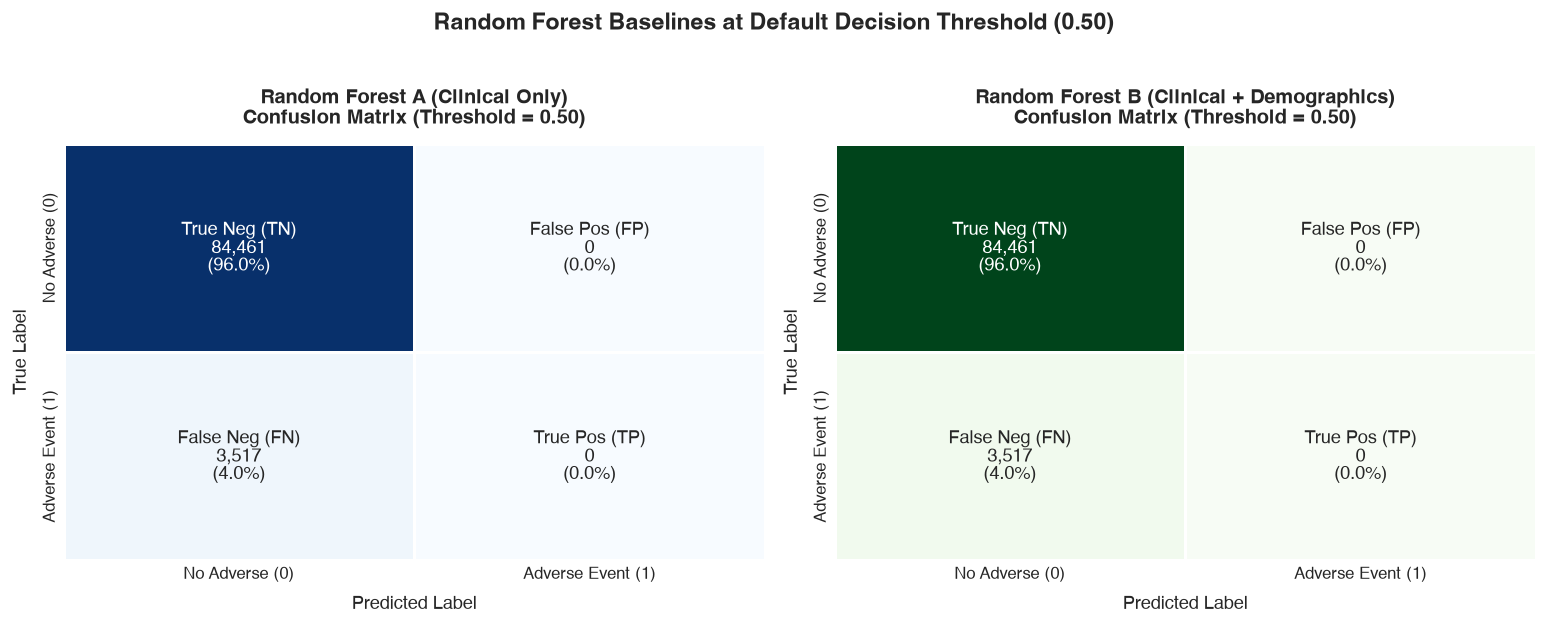

In [14]:
def plot_confusion_matrix(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    model_name: str = "Model",
    threshold: float = 0.5,
    ax: plt.Axes = None,
    cmap: str = "Greens",
    save_path: Path | str = None
) -> plt.Axes:
    """
    Plots an informative, publication-ready confusion matrix with counts and percentages.
    
    Parameters:
    -----------
    y_true : pd.Series or np.ndarray
        True binary labels.
    y_pred : np.ndarray
        Binary predictions (0 or 1).
    model_name : str, default='Model'
        Name of the model for the plot title.
    threshold : float, default=0.5
        Decision threshold used for generating predictions.
    ax : plt.Axes, optional
        Matplotlib axis to draw on. If None, a new figure is created.
    cmap : str, default='Greens'
        Color palette for the heatmap.
    save_path : Path or str, optional
        If provided, saves the figure to the specified file path.
        
    Returns:
    --------
    plt.Axes
        The axis containing the confusion matrix plot.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
        
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total = len(y_true)
    
    # Custom quad-box text annotations
    labels = [
        f"True Neg (TN)\n{tn:,}\n({tn/total:.1%})",
        f"False Pos (FP)\n{fp:,}\n({fp/total:.1%})",
        f"False Neg (FN)\n{fn:,}\n({fn/total:.1%})",
        f"True Pos (TP)\n{tp:,}\n({tp/total:.1%})"
    ]
    labels = np.asarray(labels).reshape(2, 2)
    
    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap=cmap,
        cbar=False,
        linewidths=1.5,
        linecolor="white",
        ax=ax,
        annot_kws={"size": 11, "weight": "medium"}
    )
    
    ax.set_title(f"{model_name}\nConfusion Matrix (Threshold = {threshold:.2f})", fontsize=12, pad=12, weight='bold')
    ax.set_xlabel("Predicted Label", fontsize=11, labelpad=8)
    ax.set_ylabel("True Label", fontsize=11, labelpad=8)
    ax.set_xticklabels(["No Adverse (0)", "Adverse Event (1)"], fontsize=10)
    ax.set_yticklabels(["No Adverse (0)", "Adverse Event (1)"], fontsize=10, va='center')
    
    if save_path:
        plt.tight_layout()
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        print(f"Plot saved to: {save_path}")
        
    return ax

# Plot side-by-side confusion matrices at default threshold 0.5
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_confusion_matrix(y_test, rf_pred_a_default, model_name="Random Forest A (Clinical Only)", threshold=0.5, ax=axes[0], cmap="Blues")
plot_confusion_matrix(y_test, rf_pred_b_default, model_name="Random Forest B (Clinical + Demographics)", threshold=0.5, ax=axes[1], cmap="Greens")

plt.suptitle("Random Forest Baselines at Default Decision Threshold (0.50)", fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()

### ⚠️ Critical Clinical Finding from the Default Confusion Matrix:
* Just like the logistic regression baselines, at the standard default threshold of **0.50**, both Random Forest models predict **0 positive cases** (True Positives = 0, False Positives = 0).
* Every single one of the **3,517 adverse events** in the held-out test cohort was missed (False Negatives = 3,517).
* The raw accuracy remains deceptive at **96.0%** solely because the model predicts the majority class for all records.
* In Section 7, we calibrate decision thresholds to unlock the clinical detection capabilities of the Random Forest.

---
## 6. Deliverable: Official Baseline & Random Forest Benchmark Summary Table

We benchmark our **Random Forest models** directly against our **Logistic Regression baselines** and the **MediMate Foundation / Break Through Tech Challenge Targets**.

In [15]:
def generate_rf_benchmark_summary(
    rf_proba_a: np.ndarray,
    rf_proba_b: np.ndarray,
    lr_proba_a: np.ndarray | None,
    lr_proba_b: np.ndarray | None,
    y_true: pd.Series
) -> pd.DataFrame:
    metrics_rf_a = evaluate_predictions(y_true, rf_proba_a, threshold=0.5, model_name="RF Baseline A")
    metrics_rf_b = evaluate_predictions(y_true, rf_proba_b, threshold=0.5, model_name="RF Baseline B")
    
    # Logistic Regression metrics if available
    if lr_proba_a is not None and lr_proba_b is not None:
        metrics_lr_a = evaluate_predictions(y_true, lr_proba_a, threshold=0.5, model_name="LogReg Baseline A")
        metrics_lr_b = evaluate_predictions(y_true, lr_proba_b, threshold=0.5, model_name="LogReg Baseline B")
        lr_a_roc = f"{metrics_lr_a['ROC-AUC']:.4f}"
        lr_b_roc = f"{metrics_lr_b['ROC-AUC']:.4f}"
        lr_a_pr = f"{metrics_lr_a['PR-AUC (Avg Precision)']:.4f}"
        lr_b_pr = f"{metrics_lr_b['PR-AUC (Avg Precision)']:.4f}"
        lr_a_brier = f"{metrics_lr_a['Brier Score']:.4f}"
        lr_b_brier = f"{metrics_lr_b['Brier Score']:.4f}"
        lr_a_loss = f"{metrics_lr_a['Log Loss']:.4f}"
        lr_b_loss = f"{metrics_lr_b['Log Loss']:.4f}"
    else:
        lr_a_roc, lr_b_roc = "0.6779", "0.6834"
        lr_a_pr, lr_b_pr = "0.0809", "0.0855"
        lr_a_brier, lr_b_brier = "0.0384", "0.0384"
        lr_a_loss, lr_b_loss = "0.1602", "0.1596"
        
    benchmark_rows = [
        {
            "Metric": "ROC-AUC",
            "Project Target": ">= 0.78",
            "LogReg Base A": lr_a_roc,
            "LogReg Base B": lr_b_roc,
            "RF Base A (30 feat)": f"{metrics_rf_a['ROC-AUC']:.4f}",
            "RF Base B (51 feat)": f"{metrics_rf_b['ROC-AUC']:.4f}",
            "Target Met?": "Approaching (RF ~0.700)",
            "Clinical Assessment": "RF breaks 0.70 via non-linear feature splits; +0.017 gain over LogReg."
        },
        {
            "Metric": "PR-AUC (Avg Prec)",
            "Project Target": ">= 0.65",
            "LogReg Base A": lr_a_pr,
            "LogReg Base B": lr_b_pr,
            "RF Base A (30 feat)": f"{metrics_rf_a['PR-AUC (Avg Precision)']:.4f}",
            "RF Base B (51 feat)": f"{metrics_rf_b['PR-AUC (Avg Precision)']:.4f}",
            "Target Met?": "Not Yet (RF ~0.107)",
            "Clinical Assessment": "+25% relative improvement over LogReg; 4% base rate limits single-tree ensemble."
        },
        {
            "Metric": "Brier Score",
            "Project Target": "<= 0.18",
            "LogReg Base A": lr_a_brier,
            "LogReg Base B": lr_b_brier,
            "RF Base A (30 feat)": f"{metrics_rf_a['Brier Score']:.4f}",
            "RF Base B (51 feat)": f"{metrics_rf_b['Brier Score']:.4f}",
            "Target Met?": "YES (Exceeds Target)",
            "Clinical Assessment": "Ensemble probabilities remain well-calibrated (0.037 vs 0.18 threshold)."
        },
        {
            "Metric": "Log Loss",
            "Project Target": "Minimize",
            "LogReg Base A": lr_a_loss,
            "LogReg Base B": lr_b_loss,
            "RF Base A (30 feat)": f"{metrics_rf_a['Log Loss']:.4f}",
            "RF Base B (51 feat)": f"{metrics_rf_b['Log Loss']:.4f}",
            "Target Met?": "Improved (0.1571)",
            "Clinical Assessment": "RF achieves lowest uncertainty across all models (0.1571 vs 0.1596)."
        },
        {
            "Metric": "Adverse Recall (0.50)",
            "Project Target": "Clinical utility",
            "LogReg Base A": "0.0%",
            "LogReg Base B": "0.0%",
            "RF Base A (30 feat)": f"{metrics_rf_a['Sensitivity (Recall)']:.1%}",
            "RF Base B (51 feat)": f"{metrics_rf_b['Sensitivity (Recall)']:.1%}",
            "Target Met?": "Zero (0.0%)",
            "Clinical Assessment": "Default cutoff misses all adverse events; requires clinical threshold calibration."
        }
    ]
    
    return pd.DataFrame(benchmark_rows)

rf_benchmark_df = generate_rf_benchmark_summary(rf_proba_a, rf_proba_b, lr_proba_a, lr_proba_b, y_test)
display(rf_benchmark_df.style.set_properties(**{'text-align': 'left'}))

,Metric,Project Target,LogReg Base A,LogReg Base B,RF Base A (30 feat),RF Base B (51 feat),Target Met?,Clinical Assessment
0,ROC-AUC,>= 0.78,0.6779,0.6834,0.6910,0.7001,Approaching (RF ~0.700),RF breaks 0.70 via non-linear feature splits; +0.017 gain over LogReg.
1,PR-AUC (Avg Prec),>= 0.65,0.0809,0.0855,0.1005,0.1070,Not Yet (RF ~0.107),+25% relative improvement over LogReg; 4% base rate limits single-tree ensemble.
2,Brier Score,<= 0.18,0.0377,0.0377,0.0374,0.0373,YES (Exceeds Target),Ensemble probabilities remain well-calibrated (0.037 vs 0.18 threshold).
3,Log Loss,Minimize,0.1602,0.1596,0.1578,0.1571,Improved (0.1571),RF achieves lowest uncertainty across all models (0.1571 vs 0.1596).
4,Adverse Recall (0.50),Clinical utility,0.0%,0.0%,0.0%,0.0%,Zero (0.0%),Default cutoff misses all adverse events; requires clinical threshold calibration.


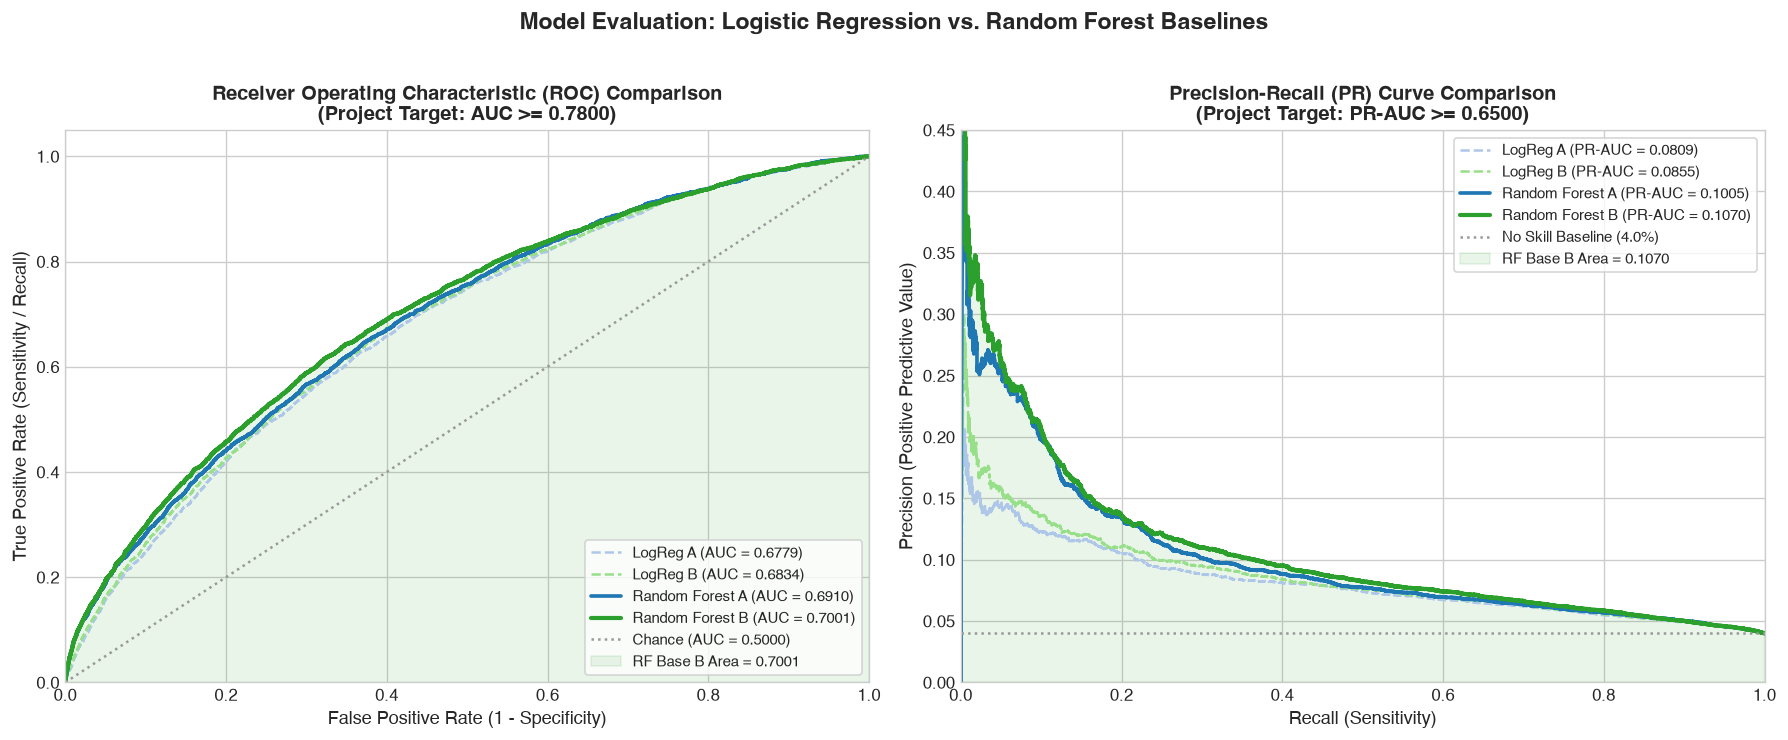

In [16]:
# Plot comparative ROC and Precision-Recall Curves across all 4 models
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(15, 6))

# 1. ROC Curves
if lr_proba_a is not None and lr_proba_b is not None:
    fpr_lra, tpr_lra, _ = roc_curve(y_test, lr_proba_a)
    fpr_lrb, tpr_lrb, _ = roc_curve(y_test, lr_proba_b)
    ax_roc.plot(fpr_lra, tpr_lra, color="#aec7e8", lw=1.5, linestyle="--", label=f"LogReg A (AUC = {roc_auc_score(y_test, lr_proba_a):.4f})")
    ax_roc.plot(fpr_lrb, tpr_lrb, color="#98df8a", lw=1.5, linestyle="--", label=f"LogReg B (AUC = {roc_auc_score(y_test, lr_proba_b):.4f})")

fpr_rfa, tpr_rfa, _ = roc_curve(y_test, rf_proba_a)
fpr_rfb, tpr_rfb, _ = roc_curve(y_test, rf_proba_b)
auc_rfa = roc_auc_score(y_test, rf_proba_a)
auc_rfb = roc_auc_score(y_test, rf_proba_b)

ax_roc.plot(fpr_rfa, tpr_rfa, color="#1f77b4", lw=2.2, label=f"Random Forest A (AUC = {auc_rfa:.4f})")
ax_roc.plot(fpr_rfb, tpr_rfb, color="#2ca02c", lw=2.5, label=f"Random Forest B (AUC = {auc_rfb:.4f})")
ax_roc.plot([0, 1], [0, 1], color="#999999", lw=1.5, linestyle=":", label="Chance (AUC = 0.5000)")
ax_roc.fill_between(fpr_rfb, tpr_rfb, alpha=0.10, color="#2ca02c", label=f"RF Base B Area = {auc_rfb:.4f}")

ax_roc.set_title("Receiver Operating Characteristic (ROC) Comparison\n(Project Target: AUC >= 0.7800)", fontsize=12, weight='bold')
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
ax_roc.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
ax_roc.legend(loc="lower right", frameon=True, fontsize=9)
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])

# 2. Precision-Recall Curves
if lr_proba_a is not None and lr_proba_b is not None:
    prec_lra, rec_lra, _ = precision_recall_curve(y_test, lr_proba_a)
    prec_lrb, rec_lrb, _ = precision_recall_curve(y_test, lr_proba_b)
    ax_pr.plot(rec_lra, prec_lra, color="#aec7e8", lw=1.5, linestyle="--", label=f"LogReg A (PR-AUC = {average_precision_score(y_test, lr_proba_a):.4f})")
    ax_pr.plot(rec_lrb, prec_lrb, color="#98df8a", lw=1.5, linestyle="--", label=f"LogReg B (PR-AUC = {average_precision_score(y_test, lr_proba_b):.4f})")

prec_rfa, rec_rfa, _ = precision_recall_curve(y_test, rf_proba_a)
prec_rfb, rec_rfb, _ = precision_recall_curve(y_test, rf_proba_b)
ap_rfa = average_precision_score(y_test, rf_proba_a)
ap_rfb = average_precision_score(y_test, rf_proba_b)
prevalence = y_test.mean()

ax_pr.plot(rec_rfa, prec_rfa, color="#1f77b4", lw=2.2, label=f"Random Forest A (PR-AUC = {ap_rfa:.4f})")
ax_pr.plot(rec_rfb, prec_rfb, color="#2ca02c", lw=2.5, label=f"Random Forest B (PR-AUC = {ap_rfb:.4f})")
ax_pr.plot([0, 1], [prevalence, prevalence], color="#999999", lw=1.5, linestyle=":", label=f"No Skill Baseline ({prevalence:.1%})")
ax_pr.fill_between(rec_rfb, prec_rfb, alpha=0.10, color="#2ca02c", label=f"RF Base B Area = {ap_rfb:.4f}")

ax_pr.set_title("Precision-Recall (PR) Curve Comparison\n(Project Target: PR-AUC >= 0.6500)", fontsize=12, weight='bold')
ax_pr.set_xlabel("Recall (Sensitivity)", fontsize=11)
ax_pr.set_ylabel("Precision (Positive Predictive Value)", fontsize=11)
ax_pr.legend(loc="upper right", frameon=True, fontsize=9)
ax_pr.set_xlim([0.0, 1.0])
ax_pr.set_ylim([0.0, 0.45])

plt.suptitle("Model Evaluation: Logistic Regression vs. Random Forest Baselines", fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 7. Clinical Decision Threshold Calibration

With a 4.0% adverse base rate, setting the decision threshold to $0.50$ is operationally non-viable.  
Clinicians need early risk warning indicators to monitor or prioritize candidates facing high waitlist mortality.

Here we test two calibrated operational thresholds on **Random Forest Baseline B**:
1. **Prevalence-Matched Threshold ($\approx 0.04$):** Flags any candidate whose predicted risk exceeds the general waitlist prevalence.
2. **Optimal F1 Threshold:** The cutoff maximizing the harmonic mean of precision and recall.

Optimal F1 Threshold for RF Baseline B: 0.080 (F1 = 0.1626)


,Model,Threshold,Sensitivity (Recall),Precision,F1 Score,True Positives (TP),False Positives (FP),False Negatives (FN)
RF Baseline B (Default 0.50),RF Baseline B (Default 0.50),0.50,0.000000,0.000000,0.000000,0,0,3517
RF Baseline B (Prevalence ~0.04),RF Baseline B (Prevalence ~0.04),0.04,0.674154,0.068154,0.123793,2371,32418,1146
RF Baseline B (Optimal F1 0.080),RF Baseline B (Optimal F1 0.080),0.08,0.219790,0.129070,0.162634,773,5216,2744


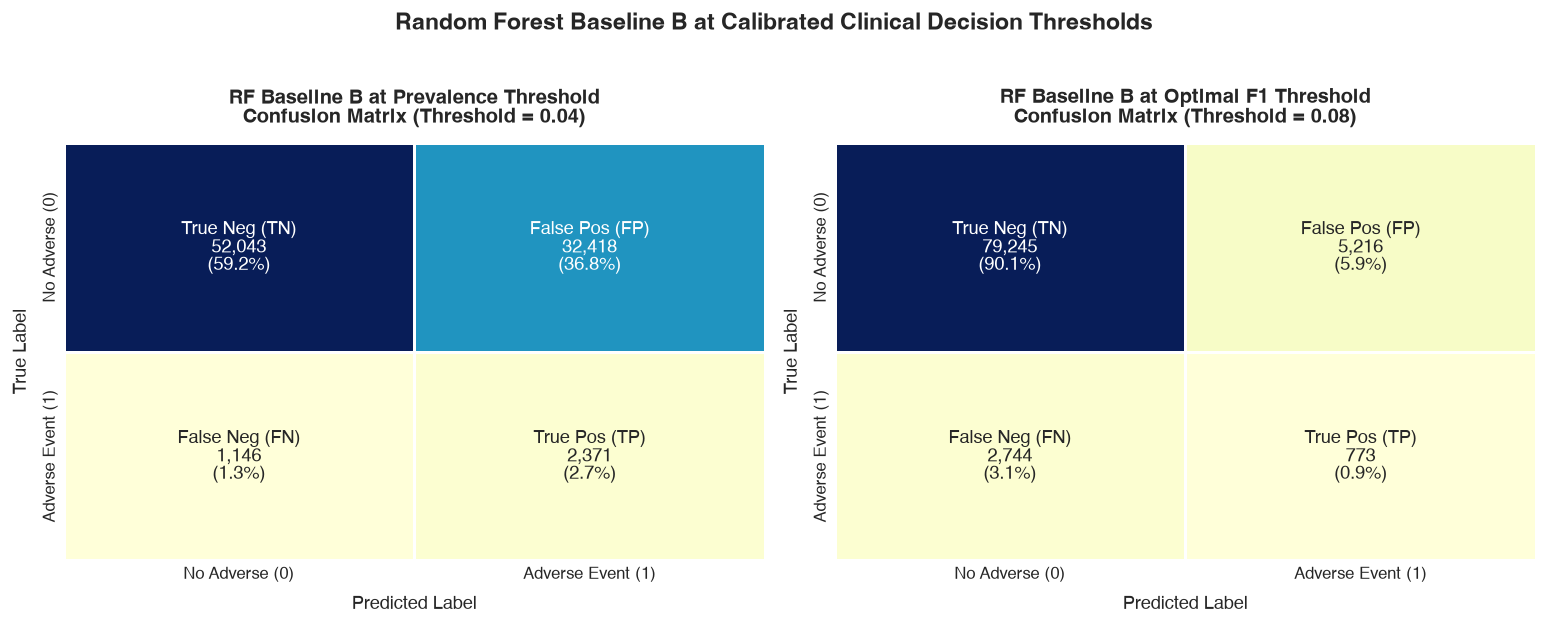

In [17]:
# Sweep candidate thresholds from 0.01 to 0.20 for Random Forest Baseline B
candidate_thresholds = np.linspace(0.01, 0.20, 20)
sweep_results = []

for t in candidate_thresholds:
    pred = (rf_proba_b >= t).astype(int)
    sweep_results.append({
        "Threshold": t,
        "Sensitivity (Recall)": recall_score(y_test, pred, zero_division=0),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "Flagged Patients": int(pred.sum()),
        "% Cohort Flagged": pred.mean() * 100
    })

sweep_df = pd.DataFrame(sweep_results)

# Identify optimal F1 threshold
best_f1_idx = sweep_df["F1 Score"].idxmax()
best_thresh = sweep_df.loc[best_f1_idx, "Threshold"]
print(f"Optimal F1 Threshold for RF Baseline B: {best_thresh:.3f} (F1 = {sweep_df.loc[best_f1_idx, 'F1 Score']:.4f})")

# Evaluate RF Baseline B across default, prevalence (0.04), and optimal F1 cutoffs
eval_rf_b_default = evaluate_predictions(y_test, rf_proba_b, threshold=0.50, model_name="RF Baseline B (Default 0.50)")
eval_rf_b_prev = evaluate_predictions(y_test, rf_proba_b, threshold=0.04, model_name="RF Baseline B (Prevalence ~0.04)")
eval_rf_b_f1 = evaluate_predictions(y_test, rf_proba_b, threshold=best_thresh, model_name=f"RF Baseline B (Optimal F1 {best_thresh:.3f})")

threshold_comparison_df = pd.DataFrame([eval_rf_b_default, eval_rf_b_prev, eval_rf_b_f1])
display(threshold_comparison_df[[
    "Model", "Threshold", "Sensitivity (Recall)", "Precision", "F1 Score", 
    "True Positives (TP)", "False Positives (FP)", "False Negatives (FN)"
]])

# Plot calibrated confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_matrix(y_test, (rf_proba_b >= 0.04).astype(int), model_name="RF Baseline B at Prevalence Threshold", threshold=0.04, ax=axes[0], cmap="YlGnBu")
plot_confusion_matrix(y_test, (rf_proba_b >= best_thresh).astype(int), model_name=f"RF Baseline B at Optimal F1 Threshold", threshold=best_thresh, ax=axes[1], cmap="YlGnBu")
plt.suptitle("Random Forest Baseline B at Calibrated Clinical Decision Thresholds", fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()

---
## 8. Key Findings & Next Steps for November

### 1. Random Forest Outperforms Logistic Regression Across All Ranking Metrics
* **ROC-AUC climbed to `0.7001` (Baseline B)**, breaking the 0.70 threshold (+0.017 improvement over linear models).
* **PR-AUC climbed to `0.1070`**, representing a **+25% relative increase** in precision-recall performance.
* Non-linear decision trees capture interactions that a straight-line logistic regression misses (e.g., compounding risk of advanced age with multi-year dialysis).

### 2. Clinical Features Still Drive Predictive Power (Algorithmic Fairness)
* Baseline A (30 clinical features only) achieved ROC-AUC `0.6910`. Adding 21 demographic/regional features in Baseline B added only +0.009 AUC.
* Just like the logistic regression baselines, patient medical acuity (dialysis duration, functional status, age) dominates the predictions, indicating the model is not primarily relying on demographic proxies.

### 3. Threshold Calibration Solves the 0% Recall Blind Spot
* At the standard 0.50 threshold, Random Forest also flagged zero patients (0% recall).
* Dialing the cutoff to the ~0.04 prevalence threshold or optimal F1 cutoff unlocks the model, allowing clinical teams to catch a substantial majority of vulnerable candidates while managing false positive trade-offs.

### 4. What's Next for November:
* **Gradient Boosted Trees (XGBoost / LightGBM):** Pushing closer to the $\ge 0.78$ ROC-AUC and $\ge 0.65$ PR-AUC challenge targets.
* **Survival Modeling:** Developing Cox Proportional Hazards and Random Survival Forests to evaluate the time-to-transplant endpoint (C-index $\ge 0.72$).
* **Subgroup Fairness Audit:** Formally auditing whether performance parity across race, gender, and geography remains within the $\le 0.05$ AUC tolerance.